In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

In [3]:
data = {
    "Study_Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Attendance": [50, 55, 60, 67, 75, 83, 85, 90, 92, 95],
    "Marks": [20, 40, 55, 60, 70, 75, 83, 90, 95, 100],
    "Assignment_Marks": [10, 12, 15, 16, 18, 20, 22, 24, 26, 28]
}

df = pd.DataFrame(data)

print("Dataset:")
print(df)

Dataset:
   Study_Hours  Attendance  Marks  Assignment_Marks
0            1          50     20                10
1            2          55     40                12
2            3          60     55                15
3            4          67     60                16
4            5          75     70                18
5            6          83     75                20
6            7          85     83                22
7            8          90     90                24
8            9          92     95                26
9           10          95    100                28


In [4]:
X_simple = df[["Study_Hours"]]

In [5]:
X_multiple = df[["Study_Hours", "Attendance", "Assignment_Marks"]]

y = df["Marks"]

In [6]:
X_train_s, X_test_s, y_train, y_test = train_test_split(X_simple, y, test_size=0.2, random_state=42)

X_train_m, X_test_m, _, _ = train_test_split(X_multiple, y, test_size=0.2, random_state=42)

In [7]:
simple_model = LinearRegression()
simple_model.fit(X_train_s, y_train)

simple_predictions = simple_model.predict(X_test_s)

In [8]:
print("\n--- Simple Linear Regression ---")
print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_[0])
print("R2 Score:", r2_score(y_test, simple_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, simple_predictions)))


--- Simple Linear Regression ---
Intercept: 23.18103448275862
Coefficient: 8.35344827586207
R2 Score: 0.9925183026896355
RMSE: 2.378662143088658


In [9]:
multiple_model = LinearRegression()
multiple_model.fit(X_train_m, y_train)

multiple_predictions = multiple_model.predict(X_test_m)

In [10]:
print("\n--- Multiple Linear Regression ---")
print("Intercept:", multiple_model.intercept_)
print("Coefficients:", multiple_model.coef_)
print("R2 Score:", r2_score(y_test, multiple_predictions))
print("RMSE:", np.sqrt(
    mean_squared_error(y_test, multiple_predictions)
))


--- Multiple Linear Regression ---
Intercept: -151.13819598506615
Coefficients: [-24.67777718   1.40311671  13.06563498]
R2 Score: 0.9715632794243748
RMSE: 4.637377484669167


In [12]:
new_student_simple = pd.DataFrame({"Study_Hours": [6]})

new_student_multiple = pd.DataFrame({
    "Study_Hours": [6],
    "Attendance": [85],
    "Assignment_Marks": [22]
})

print("\nPredicted marks using Simple Regression:",
      simple_model.predict(new_student_simple)[0])

print("Predicted marks using Multiple Regression:",
      multiple_model.predict(new_student_multiple)[0])


Predicted marks using Simple Regression: 73.30172413793103
Predicted marks using Multiple Regression: 107.50403116714477


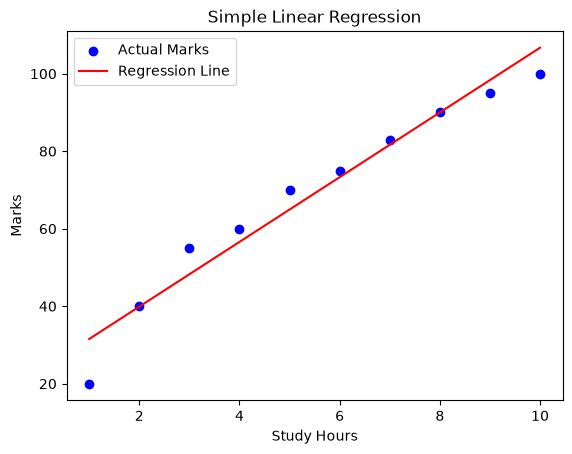

In [13]:
plt.scatter(df["Study_Hours"], df["Marks"],
            color="blue", label="Actual Marks")

plt.plot(
    df["Study_Hours"],
    simple_model.predict(X_simple),
    color="red",
    label="Regression Line"
)

plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()